## Analyzing the data

After downloading the data, we need to analyze the dataset for any missing values, shape, types, etc.

In [1]:
import pandas as pd

df = pd.read_csv("../res/MUD_malicious_urls_2026_V2.csv")
df.describe()

,label,domain_len,path_len,query_len,path_depth,subdomain_count,query_param_count,has_port,is_ip_host,has_punycode,...,phish_adv_long_domain,phish_adv_many_subdomains,phish_adv_encoded_chars,phish_adv_path_keywords,phish_adv_has_redirect,phish_adv_many_params,path_has_hacked_terms,suspicious_extension,path_underscore_count,is_gov_edu
count,632844.000000,632844.000000,632844.000000,632844.000000,632844.000000,632844.000000,632844.000000,632844.000000,632844.000000,632844.000000,...,632844.000000,632844.000000,632844.000000,632844.000000,632844.000000,632844.000000,632844.000000,632844.000000,632844.000000,632844.000000
mean,0.552266,16.627458,28.331124,11.564972,2.146155,0.413522,0.580908,0.008108,0.019062,0.000194,...,0.007438,0.002947,0.402768,0.042356,0.005000,0.368023,0.014002,0.338982,0.290632,0.000017
std,0.872202,11.197066,27.910717,34.028273,1.481682,1.016608,1.473250,0.089678,0.136742,0.013940,...,0.085922,0.054206,4.192359,0.246310,0.070531,1.193125,0.117498,0.473364,1.078205,0.004169
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,12.000000,10.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,15.000000,20.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,19.000000,38.000000,0.000000,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
max,3.000000,244.000000,2156.000000,2005.000000,38.000000,33.000000,51.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,231.000000,6.000000,1.000000,50.000000,1.000000,1.000000,64.000000,1.000000


We can see that the dataset has 83 numeric features.

In [2]:
print(df.shape)

(632844, 99)


And the other 16 features are strings, we will have to analyze them separately.

In [3]:
print(df.isna().sum()[df.isna().sum() > 0])

norm_actions    155696
path             22980
query           498121
tld                  5
dtype: int64


There are 4 features that have missing information, lets take a look at them.

In [4]:
print(df["norm_actions"].dtypes)
print(df["path"].dtypes)
print(df["query"].dtypes)
print(df["tld"].dtypes)

str
str
str
str


All of them are strings, Nan in these columns means the URL has no path, query or tld. We will be deleting them afterwards since they are already contemplated in path_len and query_len.

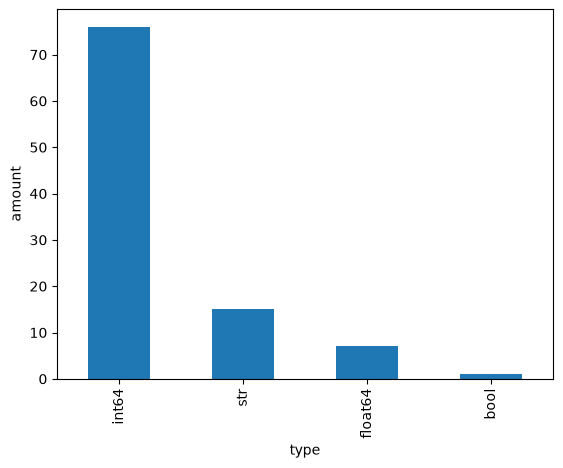

In [5]:
import matplotlib.pyplot as plt

data = df.dtypes.value_counts()
data.plot(kind="bar")
plt.xlabel("type")
plt.ylabel("amount")
plt.show()

We will need to encode the string type features so the model can take them as inputs as well.

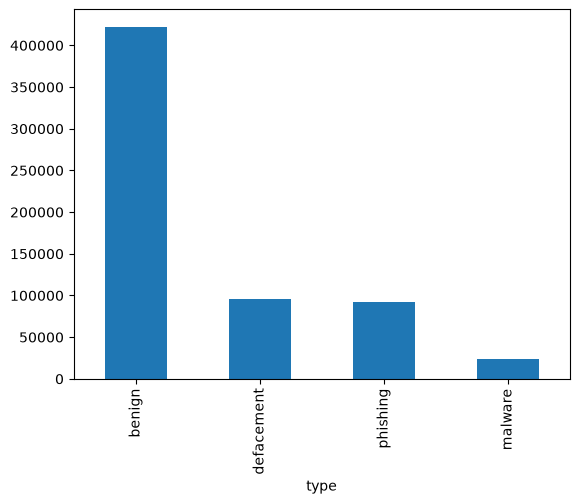

In [6]:
df["type"].value_counts().plot(kind="bar")
plt.show()

There are far more bening URLs than the other three types combined, lets see what percentage of benign and malicious URLs it has.

In [7]:
print(df["type"].value_counts(normalize=True) * 100)

type
benign        66.721182
defacement    15.056633
phishing      14.496622
malware        3.725563
Name: proportion, dtype: float64


The dataset has 66.7% of benign URLs and 33.3% of malicious URLs including defacement, phishing and malware. This helps us determine a baseline model, that guesses always benign URLs so it gets 66.7% accuracy. Our model must do better than that. Let's take a deeper look into the correlation some features have with malicious URLs.

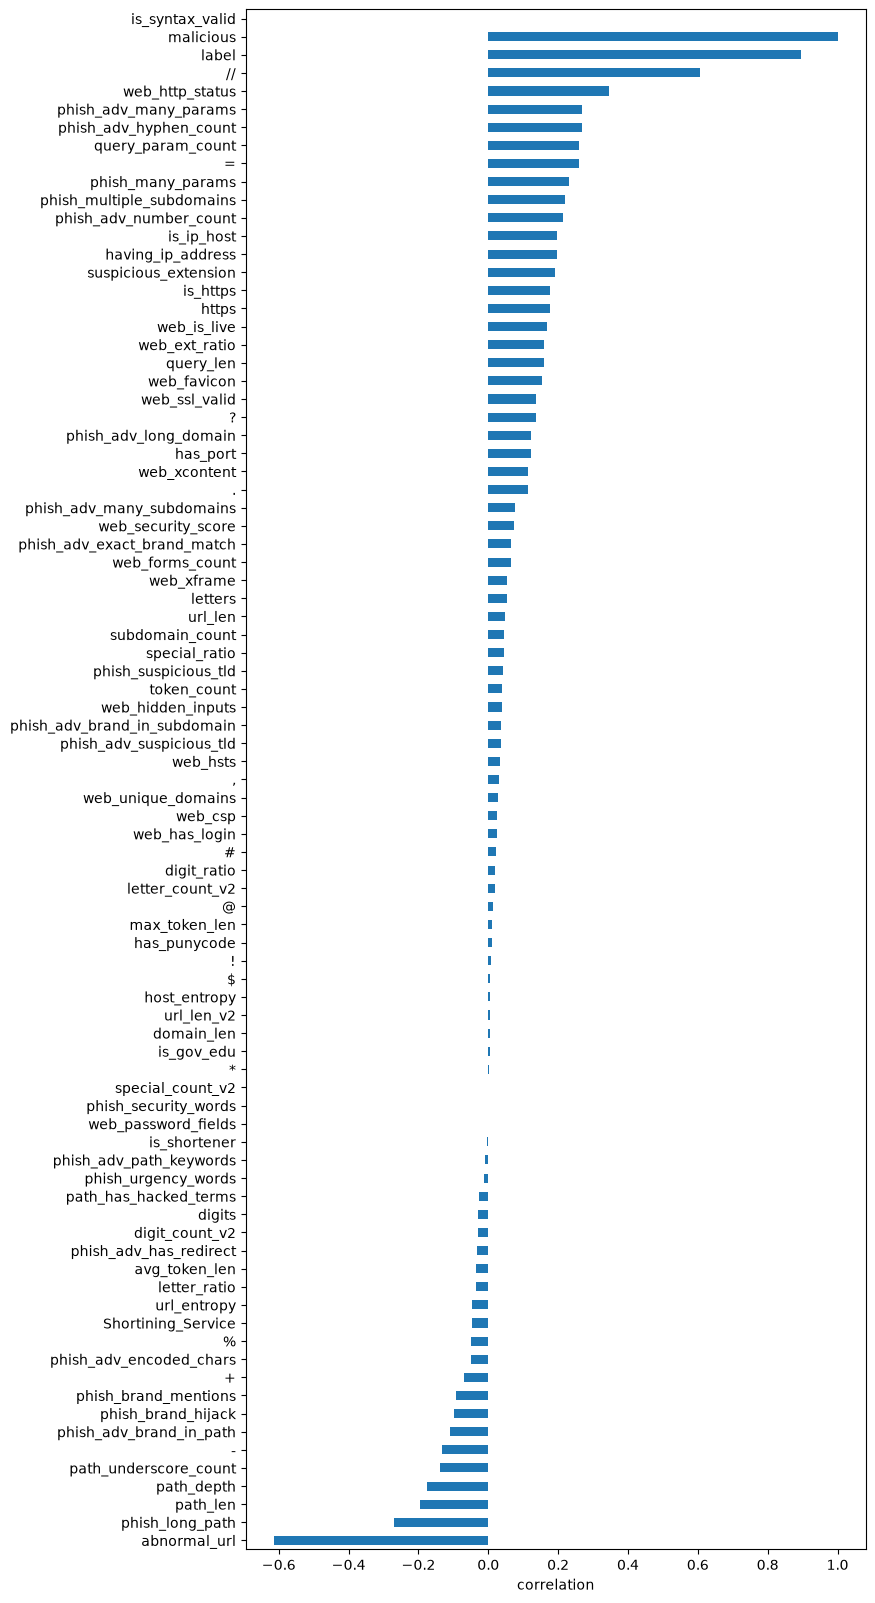

In [8]:
df["malicious"] = (df["label"] != 0).astype(int)

corr = df.corr(numeric_only=True)["malicious"].sort_values()
corr.plot(kind="barh", figsize=(8,20))
plt.xlabel("correlation")
plt.show()

We can see that features like '//' or 'web_http_status' have a positive correlation with malicious URLs (take into account that the label malicious contains every other classification than "benign"). Moreover, having 'abnormal_url' has a strong negative correlation with malicious URLs, this doesn't mean that the feature is useless, it means that 'abnormal_url' usually doesn't lead to a malicious URL.

In [ ]:
df[df["abnormal_url"] == 1]["url"].sample(10)

579450    '9d345009-a-62cb3a1a-s-sites.googlegroups.com/...
14733       bookrags.com/biography/george-catlett-marshall/
443573           signin.eby.de.jbbq0qo36p0x7uq.civpro.co.za
622485                   littlewhitedog.com/content-27.html
94184                       skillwho.com/lists/p/p0/241102/
411855    governor.wa.gov/news/news-view.asp?pressReleas...
481163                          imdb.com/name/nm0568210/bio
337781                         census-online.us/view/STULL/
557790                                    shoshian.org/aol/
26792                                    ardadisticaret.com
Name: url, dtype: str

In [15]:
df[df["abnormal_url"] == 0]["url"].sample(10)

9599      http://ruralyouthwa.org.au/index.php?option=co...
414321    http://czdesign.cz/component/sobi2/index.html?...
329865    http://scandia-rasvereniging.nl/nl/oude-scandi...
492513    http://knaresboroughkitchens.co.uk/index.php/a...
239105    http://fluidindustries.com.au/index.php?option...
74168     http://amilliondreams.eu/index.php?option=com_...
534792        http://propellertree.co.za/newfile/Tolke8.exe
105308      http://z-mobility.eu/weitere-kooperationen.html
461472                   http://naturkost-odense.dk/rogelse
275488    http://enventureonline.com/services/mechanical...
Name: url, dtype: str

It's clear that 'abnormal_url' has no https:// or http:// structure. Let's see how many URLs having 'abnormal_url' == 1 are benign.

In [18]:
df[df["abnormal_url"] == 1]["type"].value_counts(normalize=True)

type
benign      0.846634
phishing    0.150718
malware     0.002648
Name: proportion, dtype: float64

84% of all abnormal URLs are benign, if we think about it, having an abnormal url means that the URL has no scheme.

In [17]:
(df["abnormal_url"] == 1).sum() / len(df)

np.float64(0.7221447939776627)

72% of all URLs in the dataset have an abnormal url. Interesting finding.

## Conclusions

After analyzing the data we have the following findings:

- 66.7% benign and 33.3% malicious URLs
- Our baseline has an accuracy of 66.7%
- There is some missing data in the dataset
- 'abnormal_url' and '//' are among the most correlated features
- Next step: train a model and compare it against the baseline we defined